Import Required Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


Dataset Selection and Loading

In [ ]:
base_url = "https://raw.githubusercontent.com/IndustrialNetwork/GraphDataset/master/"

dataframes = []

for i in range(1, 13):
    url = base_url + f"measurements_{i}.csv"

    if i == 1:
        data = pd.read_csv(url)
    else:
        data = pd.read_csv(
            url,
            header=None,
            names=dataframes[0].columns
        )

    dataframes.append(data)

df = pd.concat(dataframes, ignore_index=True)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

Dataset loaded successfully!
Dataset shape: (100000, 301)
   Time  Tank Pressure0  Tank Pressure1  Tank Pressure2  Tank Pressure3  \
0   0.0       76.832289       57.371132       32.943856       59.739593   
1   1.0       76.737805       58.656770       32.852113       60.231390   
2   2.0       77.370212       57.430073       32.712271       59.517465   
3   3.0       76.331621       57.828447       32.922691       60.371483   
4   4.0       76.716903       57.594566       33.469707       59.683068   

   Tank Pressure4  Tank Pressure5  Tank Pressure6  Tank Pressure7  \
0       24.310363        6.322126        1.474245       59.772326   
1       23.562777        6.342027        2.042494       60.306308   
2       24.074386        7.979952        2.622159       60.385849   
3       26.298742        8.128165        4.037029       60.938240   
4       26.691073        9.979906        5.743047       60.550390   

   Tank Pressure8  ...  Tank90 Leak  Tank91 Leak  Tank92 Leak  Tank93 Leak  

Data Preprocessing

In [ ]:
print("Missing values:", df.isnull().sum().sum())

print(
    "Categorical columns:",
    df.select_dtypes(include=["object"]).columns.tolist()
)

print("Dataset shape:", df.shape)

Missing values: 0
Categorical columns: []
Dataset shape: (100000, 301)


Prepare Features and Target

In [ ]:
pressure_columns = [f"Tank Pressure{i}" for i in range(100)]
refill_columns = [f"Tank{i} Refill" for i in range(100)]
leak_columns = [f"Tank{i} Leak" for i in range(100)]

X = pd.DataFrame({
    "Pressure": df[pressure_columns].to_numpy().flatten(),
    "Refill": df[refill_columns].to_numpy().flatten()
})

y = pd.Series(df[leak_columns].to_numpy().flatten().astype(int))

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts().rename({0: "No Leak", 1: "Leak"}))

Features shape: (10000000, 2)
Target shape: (10000000,)

Target distribution:
No Leak    7319875
Leak       2680125
Name: count, dtype: int64


Visualization – Leak vs No Leak Distribution

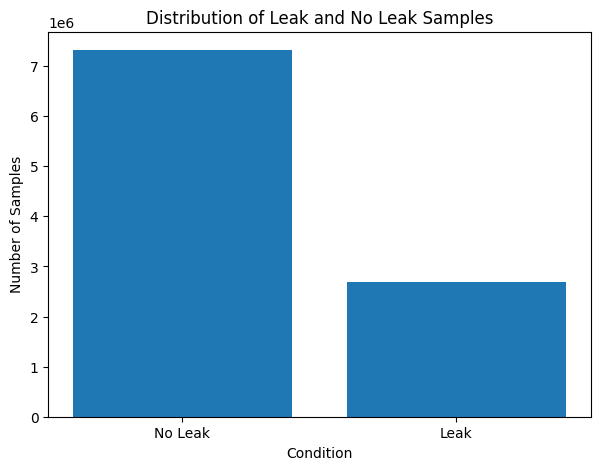

In [ ]:
label_counts = y.value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ["No Leak", "Leak"],
    label_counts.values
)

plt.title("Distribution of Leak and No Leak Samples")
plt.xlabel("Condition")
plt.ylabel("Number of Samples")

plt.show()

Train-Test Split and Standardization

In [ ]:
X_sample, _, y_sample, _ = train_test_split(
    X, y,
    train_size=20000,
    random_state=42,
    stratify=y
)

X_train, X_test, y_train, y_test = train_test_split(
    X_sample, y_sample,
    test_size=0.2,
    random_state=42,
    stratify=y_sample
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training data: (16000, 2)
Testing data: (4000, 2)

Training labels:
0    11712
1     4288
Name: count, dtype: int64

Testing labels:
0    2928
1    1072
Name: count, dtype: int64


Visualization – Pressure Distribution

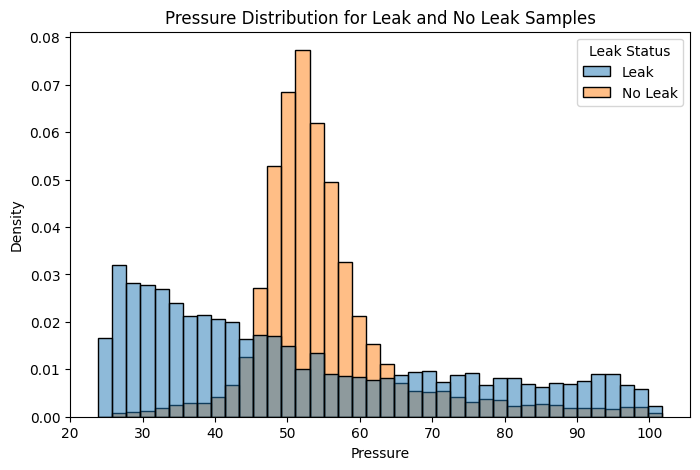

In [ ]:
pressure_data = X_sample.copy()
pressure_data["Leak Status"] = y_sample.map({
    0: "No Leak",
    1: "Leak"
})

plt.figure(figsize=(8, 5))

sns.histplot(
    data=pressure_data,
    x="Pressure",
    hue="Leak Status",
    bins=40,
    stat="density",
    common_norm=False,
    alpha=0.5
)

plt.title("Pressure Distribution for Leak and No Leak Samples")
plt.xlabel("Pressure")
plt.ylabel("Density")

plt.show()

Models Training

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(random_state=42)
}

training_times = {}

for name, model in models.items():
    start_time = time.time()

    model.fit(X_train, y_train)

    training_times[name] = time.time() - start_time

    print(f"{name} trained successfully!")

print("\nAll four models trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
SVM trained successfully!

All four models trained successfully!


Performance Evaluation

In [ ]:
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

              Model  Accuracy  Precision   Recall  F1-Score
Logistic Regression     0.775   0.917476 0.176306  0.295775
      Decision Tree     0.788   0.610020 0.579291  0.594258
      Random Forest     0.788   0.610020 0.579291  0.594258
                SVM     0.851   0.850000 0.539179  0.659817


Visualization – Confusion Matrices

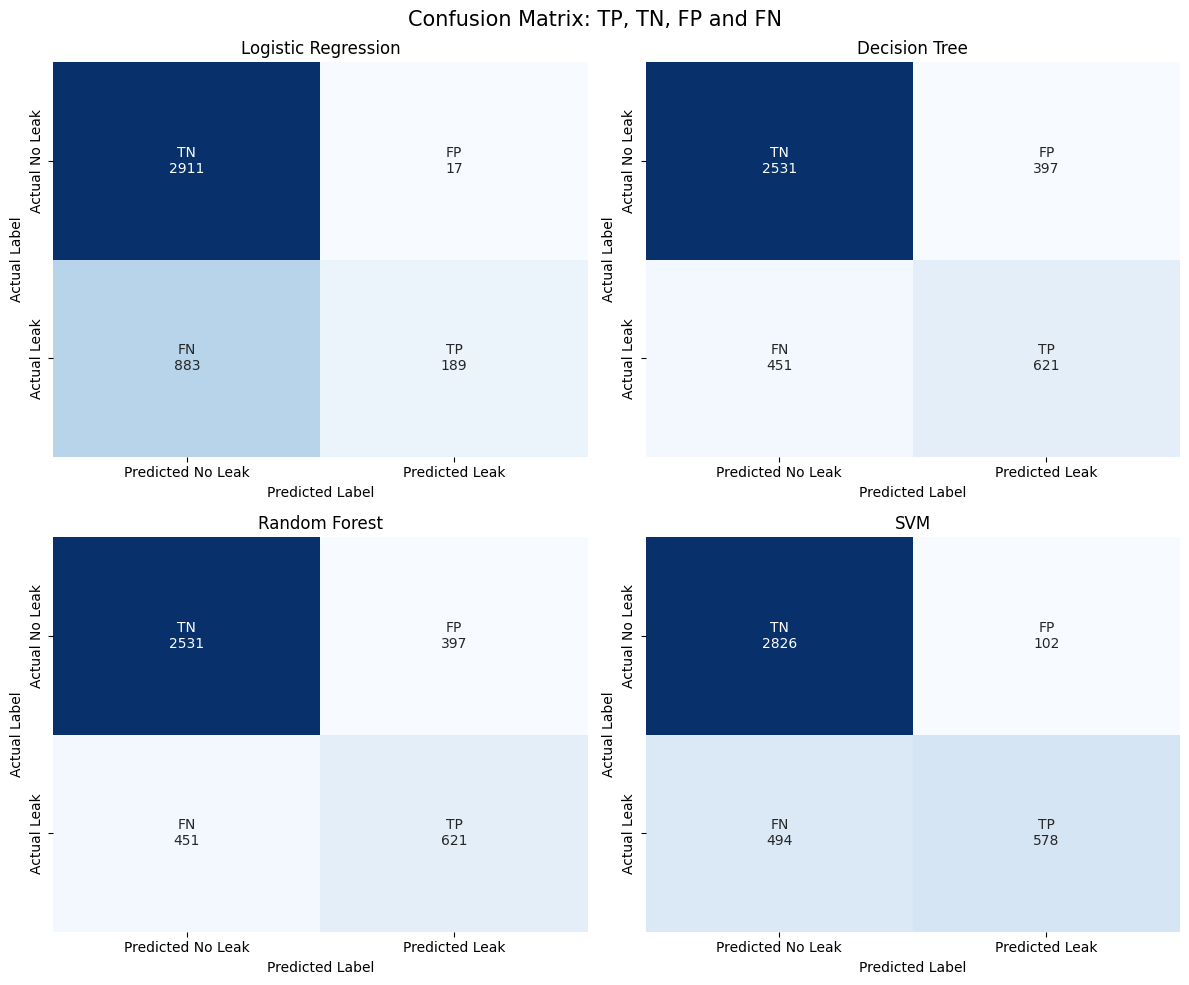

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for (name, model), ax in zip(models.items(), axes.flatten()):

    y_pred = model.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    cm_labels = [
        [f"TN\n{tn}", f"FP\n{fp}"],
        [f"FN\n{fn}", f"TP\n{tp}"]
    ]

    sns.heatmap(
        [[tn, fp], [fn, tp]],
        annot=cm_labels,
        fmt="",
        cmap="Blues",
        cbar=False,
        xticklabels=["Predicted No Leak", "Predicted Leak"],
        yticklabels=["Actual No Leak", "Actual Leak"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle("Confusion Matrix: TP, TN, FP and FN", fontsize=15)
plt.tight_layout()
plt.show()

Visualization – Model Performance Comparison

<Figure size 1000x600 with 0 Axes>

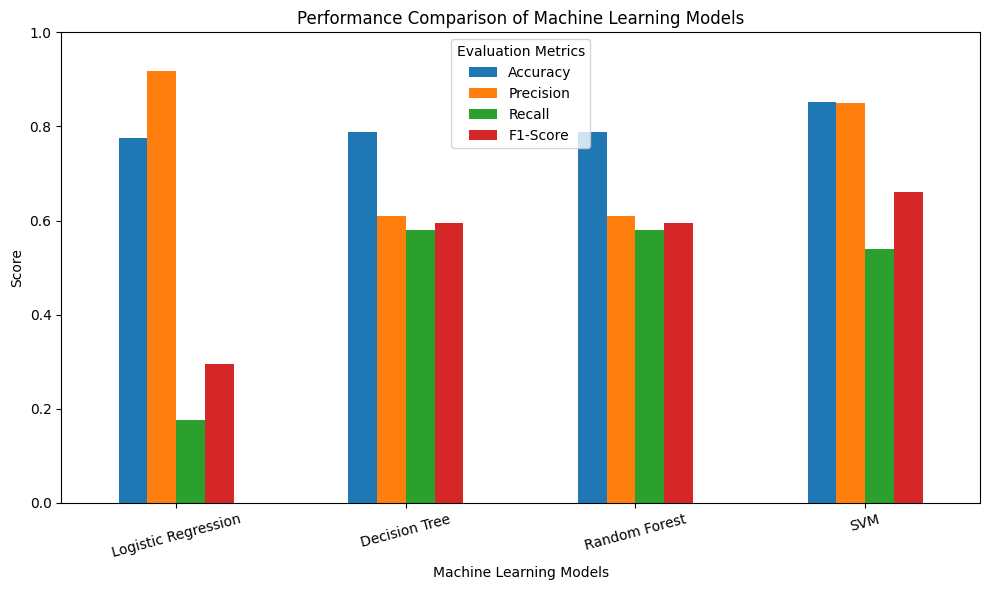

In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

plt.figure(figsize=(10, 6))

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(title="Evaluation Metrics")
plt.tight_layout()

plt.show()